# Black hole mass from a J-PAS photospectrum

This notebook shows the basic usage of `quasar_lines`:

1. load the photospectrum of a quasar observed by miniJPAS,
2. fit its continuum and broad emission lines,
3. plot the result,
4. compute the black hole virial mass.

The example quasar (miniJPAS 2406-853, SDSS 7339-56722-0108) is at $z=0.676$, so both H$\beta$ and MgII fall within the J-PAS wavelength range.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import quasar_lines as ql

## 1. Load the data

The catalogue contains the flux density $F_\lambda$ [erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$] and its uncertainty in each J-PAS band (columns `J0378` ... `J1007` and `eJ0378` ... `eJ1007`), together with the SDSS redshift (`zspec`). The J-PAS transmission curves are bundled with the package.

In [2]:
cat = ql.read_minijpas_catalog("../examples/data/minijpas_qso_examples.cat")
filters = ql.load_jpas_filters(cat.band_names)

ii = 0  # source to fit
flux, flux_err, z = cat.flux[ii], cat.flux_err[ii], cat.z[ii]
print(f"{len(cat)} sources, {len(filters)} bands; fitting source {ii} at z = {z:.3f}")

3 sources, 55 bands; fitting source 0 at z = 0.676


We also load the SDSS spectrum of the same quasar, only for comparison.

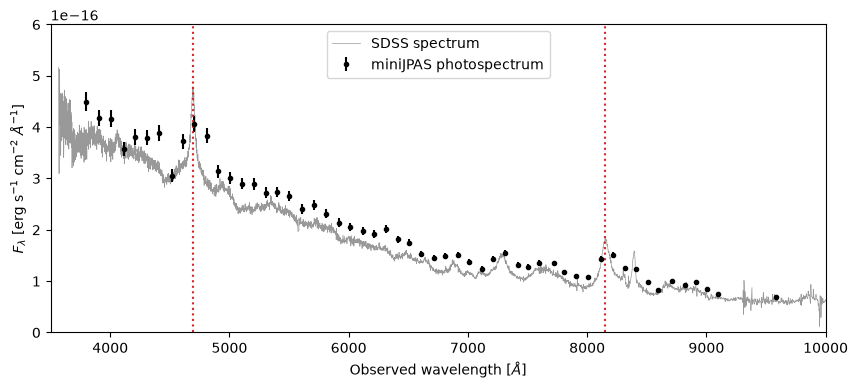

In [3]:
sdss_wav, sdss_flux, _ = ql.read_sdss_spectrum("../examples/data/spec-7339-56722-0108.fits")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sdss_wav, sdss_flux, color="0.6", lw=0.5, label="SDSS spectrum")
ax.errorbar(filters.pivot, flux, flux_err, fmt="o", ms=3, color="k", label="miniJPAS photospectrum")
for line in ql.LINES:
    ax.axvline(line.rest_wavelength * (1 + z), ls=":", color="C3")
ax.set_xlim(3500, 10000)
ax.set_ylim(0, 6e-16)
ax.set_xlabel(r"Observed wavelength [$\AA$]")
ax.set_ylabel(r"$F_\lambda$ [erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]")
ax.legend();

## 2. Fit the photospectrum

`fit_photospectrum` first fits a power-law continuum and then each broad line (H$\beta$, MgII, CIV) within the observed range, forward-modelling the line through the filter curves. Both steps use MCMC (`emcee`); `rng` makes the result reproducible. It takes a few seconds.

In [4]:
fit = ql.fit_photospectrum(flux, flux_err, z, filters, rng=42)
print(fit.summary())

Photospectrum fit at z = 0.6760
  continuum slope alpha = -2.16 (+0.12 / -0.13)
  Hbeta:
    center      = 4880.2 A (rest frame; posterior above half max: 4872.0-4887.9)
    FWHM        = 5322 (+1410 / -1677) km/s
    EW          = 69.4 (+9.9 / -10.3) A (rest frame)
    log L5100 = 45.21 (+0.02 / -0.02) erg/s
    log M_BH    = 8.65 +/- 0.27 M_sun (chaves-montero22)
  MgII:
    center      = 2836.0 A (rest frame; posterior above half max: 2817.3-2847.5)
    FWHM        = 8118 (+5690 / -5865) km/s
    EW          = 32.8 (+10.2 / -9.3) A (rest frame)
    log L3000 = 45.48 (+0.02 / -0.02) erg/s
    log M_BH    = 8.98 +/- 0.79 M_sun (chaves-montero22)


## 3. Plot the result

Black dots are the photospectrum, the blue line the continuum, solid coloured lines the best-fitting line profiles, and diamonds those profiles integrated through the filters (what is actually compared with the data).

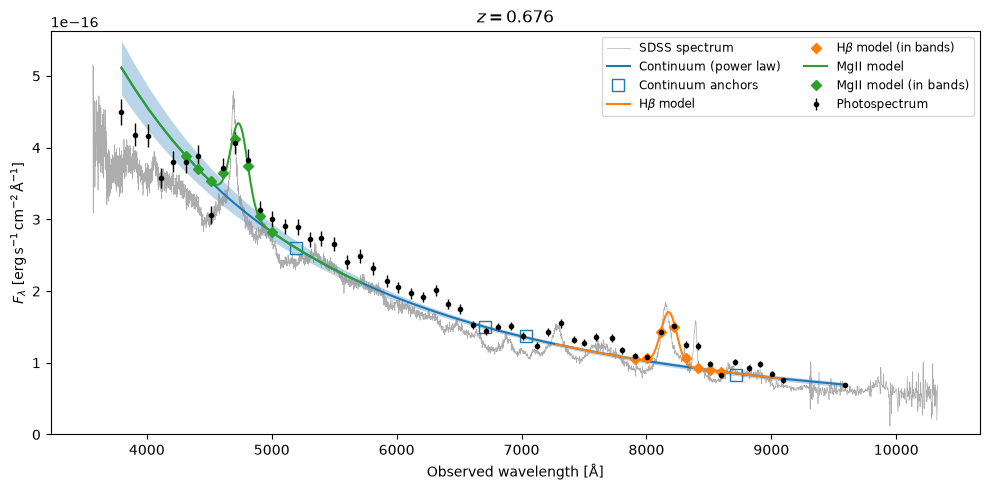

In [5]:
ax = ql.plot_fit(fit, spectrum=(sdss_wav, sdss_flux), spectrum_label="SDSS spectrum")
ax.figure.tight_layout()

Every line fit keeps its posterior samples, e.g. the posterior of the H$\beta$ FWHM:

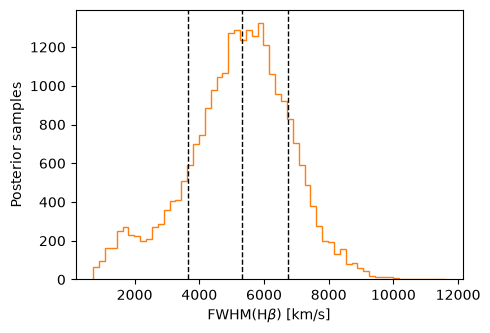

In [6]:
hb = fit.lines["Hbeta"]
fwhm_kms = ql.conversions.width_aa_to_kms(hb.center[0] * (1 + z), hb.profile.fwhm(*hb.samples.T))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(fwhm_kms, bins=60, histtype="step", color="C1")
for value in hb.fwhm:
    ax.axvline(value, ls="--", color="k", lw=1)
ax.set_xlabel(r"FWHM(H$\beta$) [km/s]")
ax.set_ylabel("Posterior samples");

## 4. Black hole mass

Virial masses combine the continuum luminosity and the line FWHM:
$\log(M_\mathrm{BH}/M_\odot) = A + B\,[\log(\lambda L_\lambda) - 44] + 2\log(\mathrm{FWHM})$.

By default we use the coefficients recalibrated for single-epoch photometry by Chaves-Montero et al. (2022); `calibration="shen11"` uses the standard spectroscopic ones.

In [7]:
for calibration in ["chaves-montero22", "shen11"]:
    print(calibration)
    masses = fit.black_hole_mass(calibration)
    edd = fit.eddington_ratio(calibration)
    for name, (mbh, err) in masses.items():
        print(f"  {name:6s} log M_BH = {mbh:.2f} +/- {err:.2f}   log L/L_Edd = {edd[name][0]:.2f}")

chaves-montero22
  Hbeta  log M_BH = 8.65 +/- 0.27   log L/L_Edd = -0.57
  MgII   log M_BH = 8.98 +/- 0.79   log L/L_Edd = -0.89
shen11
  Hbeta  log M_BH = 8.97 +/- 0.27   log L/L_Edd = -0.89
  MgII   log M_BH = 9.47 +/- 0.79   log L/L_Edd = -1.39


## Using your own data

* Other J-PAS sources: put their fluxes in a catalogue with the same format, or pass arrays directly to `ql.fit_photospectrum(flux, flux_err, z, filters)`.
* Other filter systems: build `ql.FilterSet(wavelength, transmission, names)` from your transmission curves (all sampled with the same number of points, sorted by wavelength).
* Many sources: `ql.fit_catalog(...)` or `scripts/run_catalog.py` (MPI-parallel).